In [1]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.signal import periodogram
sys.path.append("../")
from analysis import System

def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

In [2]:
voltages = ["1", "1.5", "2", "5", "10"]
l = System("michelson", ["../../data/20261015/" + j + "V_no_mask_44mW_Pin/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 4)], set_data = True, channel = "X")

../../data/20261015/1.5V_no_mask_44mW_Pin/iter_1.tdms


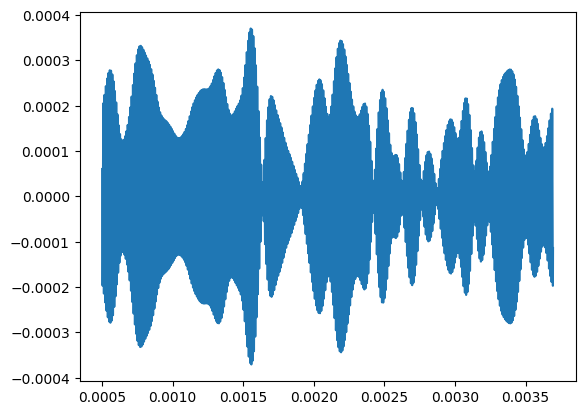

(1e-16, 1e-08)

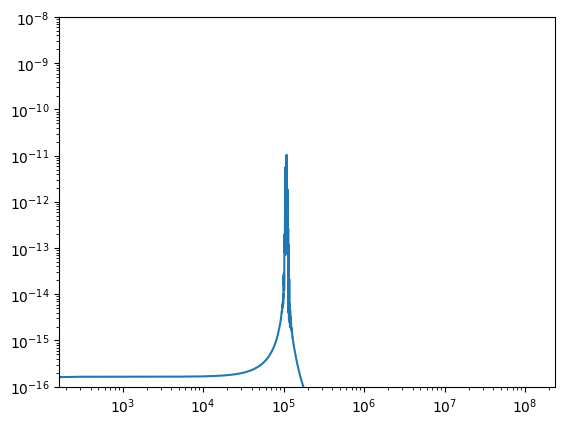

In [88]:
idx = 5
print(l.get_df()[idx])
col = 0
freq = 109e3
r = 5e3
l.set_data(ind = idx)
l.get_data()[idx].apply("detrend", mode = "linear", inplace = True)
l.get_data()[idx].apply("filter", cutoff = [freq - r, freq + r], btype = "bandpass", inplace = True)
l.get_data()[idx].apply("time_gate", tmin = l.get_data()[idx].collection[col].t[0] + 5e-4, tmax = l.get_data()[idx].collection[col].t[-1] - 5e-4, inplace = True)
plt.plot(l.get_data()[idx].collection[col].t, l.get_data()[idx].collection[col].x)
plt.show()
f, p = periodogram(l.get_data()[idx].collection[col].x, l.get_data()[idx].r)
plt.loglog(f, p)
# plt.xlim(1e4, 1e6)
plt.ylim(1e-16, 1e-8)

SNR in 238 Hz: 8.9 dB  (+1.0/-1.3 dB)
SNR in 238 Hz: 10.4 dB  (+0.7/-0.8 dB)
SNR in 238 Hz: 12.9 dB  (+0.8/-0.9 dB)
SNR in 238 Hz: 22.2 dB  (+0.6/-0.6 dB)
SNR in 238 Hz: 26.5 dB  (+0.2/-0.2 dB)


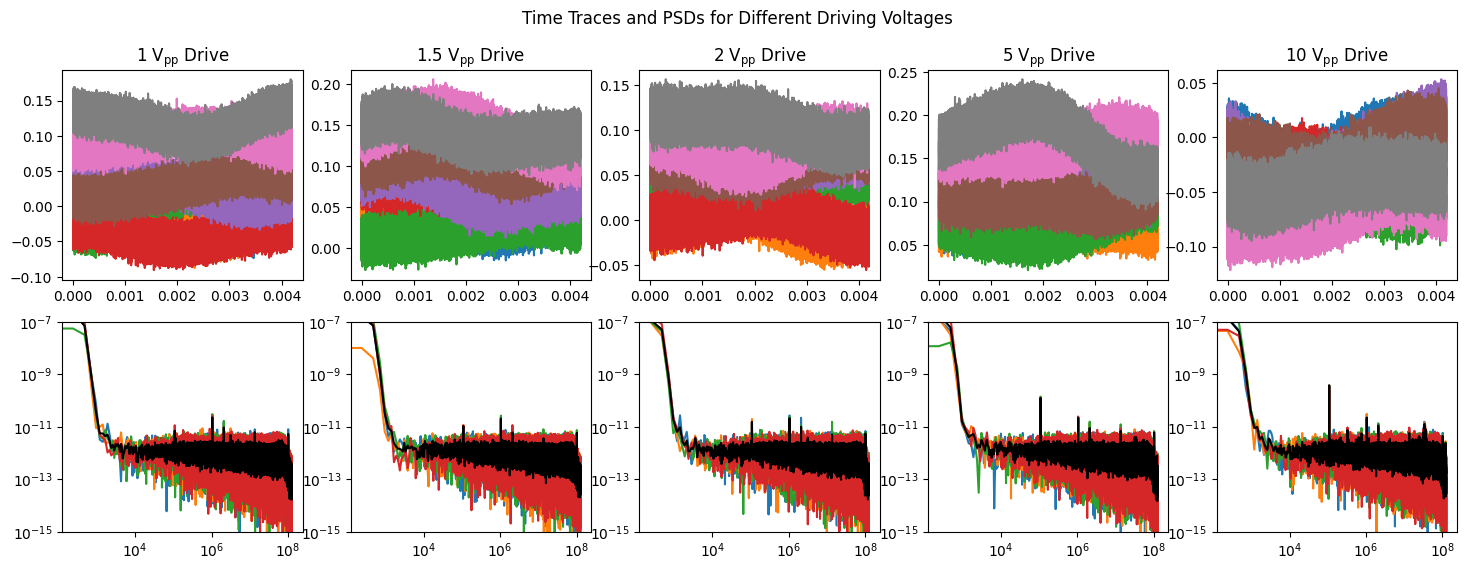

Bad pipe message: %s [b'\xf8+\xe13\x88\x94H_5\xf5\xd4Z\xbeh\xa8\xd7o\xc0\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00\xa4\x00\xa5\x00\xa6\x00\xa7\x00\xba\x00\xbb\x00\xbc\x00\xbd\x00\xbe\x00\xbf\x00\xc0\x00\xc1\x00\xc2\x00\xc3\x00\xc4\x00\xc5\x13\x01\x13\x02\x13\x03\x13\x04\x13\x05\xc0\x01\xc0\x02\xc0\x03\xc0\x04\xc0\x05\xc0\x06\xc0\x07\xc0\x08\xc0\t\xc0\n\xc0\x0b\xc0\x0c\xc0\r\xc0\x0e']
Bad pipe message: %s [b"\xc0\x10\xc0\x11\xc0\x12\xc0\x13\xc0\x14\xc0\x15\xc0\x16\xc0\x17\xc0\x18\xc0\x19\xc0#

In [157]:
fig, ax = plt.subplots(2, 5, figsize = (18, 6))
freq = 109e3
r = 10e3
for i in range(0, 20):
    l.set_data(ind = i)
    d = l.get_data()[i]
    # d.apply("detrend", mode = "linear", inplace = True)
    # d.apply("filter", cutoff = [freq - r, freq + r], btype = "bandpass", inplace = True)
    # d.apply("filter", btype = "highpass", cutoff = 6e4, inplace = True)
    # d.apply("time_gate", tmin = d.collection[0].t[0] + 5e-4, tmax = d.collection[0].t[-1] - 5e-4, inplace = True)
    ax[0][i // 4].plot(d.collection[0].t, d.collection[0].x)
    ax[0][i // 4].plot(d.collection[1].t, d.collection[1].x)
    
    f, p0 = periodogram(d.collection[0].x, d.r, window = "hann", detrend = "linear")
    # ax[1][i // 4].loglog(f, p0)
    _, p1 = periodogram(d.collection[1].x, d.r, window = "hann", detrend = "linear")
    # ax[1][i // 4].loglog(f, p1)

    if i % 4 == 0:
        P = []
    p = np.array((p0 + p1) / 2)
    ax[1][i // 4].loglog(f, p)
    P.append(p)
    if i % 4 == 3:
        P = np.array(P)
        Pm = np.mean(P, axis = 0)
        std = np.std(P, axis = 0)
        ax[1][i // 4].loglog(f, Pm, c = "k")

        df = f[1] - f[0]
        ix = np.argmin(np.abs(f - freq))
        ix += np.argmax(Pm[ix - 3 : ix + 4]) - 3
        pk = slice(ix - 4, ix + 5)
        nb = (np.abs(f - f[ix]) > 20 * df) & (np.abs(f - f[ix]) < 100 * df)
        assert nb.sum() > 50, f"only {nb.sum()} noise bins"
        Sn = np.mean(Pm[nb])
        Psig = np.sum(Pm[pk] - Sn) * df
        if Psig <= 0:
            print("no detection: Psig <", 3 * np.std(Pm[nb]) * np.sqrt(9) * df, "V^2")
        else:
            # print(f"SNR in {df:.0f} Hz: {10 * np.log10(Psig / (Sn * df)):.1f} dB,  C/N0: {10 * np.log10(Psig / Sn):.1f} dB-Hz")
            snrs = [np.sum(Pi[pk] - np.mean(Pi[nb])) / np.mean(Pi[nb]) for Pi in P]
            m, e = np.mean(snrs), np.std(snrs, ddof=1) / np.sqrt(len(snrs))
            print(f"SNR in {df:.0f} Hz: {10*np.log10(m):.1f} dB  (+{10*np.log10((m+e)/m):.1f}/-{10*np.log10(m/(m-e)):.1f} dB)")

fig.suptitle("Time Traces and PSDs for Different Driving Voltages")
for i in range(0, 5):
    ax[0][i].set_title(f"{voltages[i]} V$_{{\\text{{pp}}}}$ Drive")
    # ax[1][i].set_xlim(5e4, 3e5)
    ax[1][i].set_ylim(1e-15, 1e-7)
plt.show()